# Do rises and falls predict volatility differently?

HAR uses today's realized variance as one number. SHAR (Patton & Sheppard,
2015) splits it into the variance from rising and from falling returns, the
semivariances defined in `01_data`, and lets each carry its own weight. This
notebook asks, for every asset, whether the two weights differ, and whether
SHAR forecasts better than HAR because of it.

Methods (walk-forward, smearing, QLIKE, the DM test) are explained in
`02_har`. Every number that depends on the data is printed by the code cell it
comes from.

In [1]:
import _plots
import pandas as pd
from _common import CANDIDATE, COLORS, LOSS, by_asset, pair, runs

from rvol import study

_plots.use_style()

## 1. The model

$$
y_{t+1} = a + b^+ \log \mathrm{RS}^+_t + b^- \log \mathrm{RS}^-_t
  + b_w\,\bar y^{(w)}_t + b_m\,\bar y^{(m)}_t
$$

with $y = \log \mathrm{RV}$ and the weekly and monthly means as in HAR. Patton
and Sheppard use levels; logs here match HAR. In stocks, falls usually predict
more volatility than rises ($b^- > b^+$). For a currency pair the sign only says
which currency strengthened, so there is no strong prior either way.

The coefficients fitted on everything before the evaluation period:

In [2]:
RUNS = runs()
RISE, FALL = study.LOG_RS_POS.column(1), study.LOG_RS_NEG.column(1)


def model(run, name):
    return next(m for m in run.models if m.name == name)


def fitted_coefficients(run, name, origin):
    chosen = model(run, name)
    known = run.prepared.loc[run.prepared["target_date"] < pd.Timestamp(origin)]
    fit = chosen.rule.fit(known[list(chosen.regressors)].to_numpy(), known["target"].to_numpy())
    return pd.Series([fit.intercept, *fit.coefficients], index=["intercept", *chosen.regressors])


tables = {}
for asset, run in RUNS.items():
    har = fitted_coefficients(run, CANDIDATE, study.EVALUATION_START)
    shar = fitted_coefficients(run, "SHAR", study.EVALUATION_START)
    rows = list(dict.fromkeys([*har.index, *shar.index]))
    tables[asset] = pd.DataFrame({CANDIDATE: har, "SHAR": shar}).loc[rows]
    print(f"{pair(asset)}: b+ = {shar[RISE]:.2f} on today's rises, b- = {shar[FALL]:.2f} on falls")
by_asset(tables).round(3)

EUR/USD: b+ = 0.14 on today's rises, b- = 0.03 on falls


HAR   SHAR
asset                                  
EUR/USD intercept         -1.692 -1.557
        log_rv_mean_1      0.125    NaN
        log_rv_mean_5      0.468  0.441
        log_rv_mean_22     0.255  0.248
        log_rs_pos_mean_1    NaN  0.135
        log_rs_neg_mean_1    NaN  0.026

One fit can mislead, so here are SHAR's two slopes as the walk-forward refits
them at the start of each quarter of the evaluation period.

In [3]:
quarters = pd.date_range(study.EVALUATION_START, study.FORECAST_END, freq="QS")
refits = {}
for asset, run in RUNS.items():
    day_after = {origin.date(): origin + pd.Timedelta(days=1) for origin in quarters}
    slopes = pd.DataFrame(
        {
            day: fitted_coefficients(run, "SHAR", after)[[RISE, FALL]]
            for day, after in day_after.items()
        }
    ).T.set_axis(["b+", "b-"], axis=1)
    refits[asset] = slopes
    above = (slopes["b+"] > slopes["b-"]).sum()
    print(f"{pair(asset)}: b+ above b- at {above} of {len(slopes)} quarterly refits")
by_asset(refits, name="asset").rename_axis(["asset", "refit at"]).round(3)

EUR/USD: b+ above b- at 7 of 7 quarterly refits


b+     b-
asset   refit at                
EUR/USD 2025-01-01  0.135  0.026
        2025-04-01  0.151  0.031
        2025-07-01  0.181  0.028
        2025-10-01  0.151  0.054
        2026-01-01  0.142  0.055
        2026-04-01  0.187  0.070
        2026-07-01  0.177  0.075

The refit "at" a date uses every outcome observed up to and including that
date, as the walk-forward does for a forecast made that day.

## 2. Does SHAR forecast better?

The study tests every model against HAR, so the p-value there asks whether HAR
is better than SHAR. Here the question is the reverse: whether SHAR is better
than HAR, with $d_t$ = HAR's loss minus SHAR's, repeated across HAC lags as in
`02_har`. Two descriptive checks go with it: the months in which SHAR does
better, and the share of its advantage that comes from its ten best sessions.

In [4]:
from rvol.evaluation import default_hac_lags, diebold_mariano

reverse, summaries, GAIN = {}, {}, {}
for asset, run in RUNS.items():
    losses = run.comparison.losses.pivot(index="target_date", columns="model", values="loss")
    gain = losses[CANDIDATE] - losses["SHAR"]
    GAIN[asset] = gain
    usual = default_hac_lags(len(losses))
    hac_lags = sorted({*range(usual + 1), 2 * usual, 4 * usual, 6 * usual})
    p = pd.Series(
        [diebold_mariano(losses[CANDIDATE], losses["SHAR"], hac_lags=lag)[1] for lag in hac_lags],
        index=pd.Index(hac_lags, name="hac_lags"),
        name="p-value, SHAR better",
    )
    reverse[asset] = p
    months = gain.groupby(gain.index.to_period("M")).mean()
    table = study.results_table(run.comparison)
    har_loss = table.loc[CANDIDATE, LOSS]
    share = f"{gain.nlargest(10).sum() / gain.sum():.0%}" if gain.sum() > 0 else "no advantage"
    summaries[pair(asset)] = {
        f"{LOSS}, {CANDIDATE}": f"{har_loss:.4f}",
        f"{LOSS}, SHAR": f"{table.loc['SHAR', LOSS]:.4f}",
        f"SHAR's mean loss below {CANDIDATE}'s by": f"{1 - table.loc['SHAR', LOSS] / har_loss:.1%}",
        "sessions SHAR wins": f"{(gain > 0).mean():.0%}",
        "months SHAR wins": f"{(months > 0).sum()} of {len(months)}",
        "advantage from its 10 best sessions": share,
    }
    print(f"{pair(asset)}: one-sided p from {p.min():.3f} to {p.max():.3f} across lags")
display(pd.DataFrame(reverse).T.rename(index=pair).style.format("{:.3f}"))
pd.DataFrame(summaries)

EUR/USD: one-sided p from 0.021 to 0.059 across lags


hac_lags,0,1,2,3,4,5,10,20,30
EUR/USD,0.021,0.030,0.033,0.034,0.034,0.035,0.042,0.047,0.059


,EUR/USD
"QLIKE, HAR",0.1525
"QLIKE, SHAR",0.1510
SHAR's mean loss below HAR's by,1.0%
sessions SHAR wins,52%
months SHAR wins,10 of 21
advantage from its 10 best sessions,99%


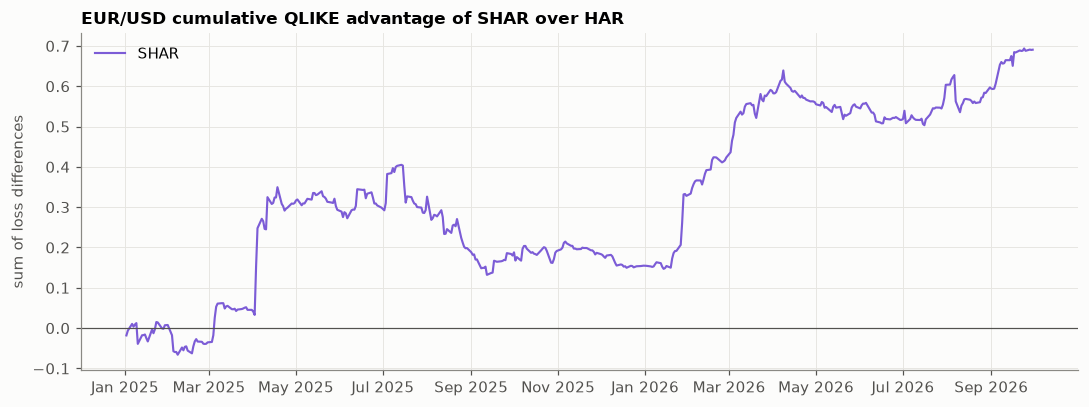

In [5]:
_plots.cumulative_advantage(
    {pair(a): gain.cumsum().to_frame("SHAR") for a, gain in GAIN.items()},
    COLORS,
    title=f"cumulative {LOSS} advantage of SHAR over {CANDIDATE}",
);

A line that rises steadily is a steady advantage; a line that jumps on a few
days and drifts otherwise is an advantage that rests on those days.

## Answer

In [6]:
for asset, slopes in refits.items():
    p = reverse[asset]
    if (slopes["b+"] > slopes["b-"]).all():
        print(f"{pair(asset)}: b+ > b- at every quarterly refit")
    elif (slopes["b-"] > slopes["b+"]).all():
        print(f"{pair(asset)}: b- > b+ at every quarterly refit")
    else:
        print(f"{pair(asset)}: the slopes' order changes between refits")
    if p.max() < 0.05:
        verdict = "significant at 5% at every lag"
    elif p.min() < 0.05:
        verdict = "significant at 5% at some lags only"
    else:
        verdict = "not significant at 5% at any lag"
    print(f"   SHAR better than {CANDIDATE}: {verdict} (p from {p.min():.3f} to {p.max():.3f})")

EUR/USD: b+ > b- at every quarterly refit
   SHAR better than HAR: significant at 5% at some lags only (p from 0.021 to 0.059)


Two questions, two kinds of answer. Whether rises and falls carry different
weight is answered by the slopes and their stability across refits. Whether
that makes SHAR the better forecast is a weaker claim: an edge that is
borderline in the DM test and concentrated in a few sessions is suggestive,
not decisive.

**Caveats.** SHAR was added after HAR was fixed as the candidate, and its test
here is one of several pairwise comparisons, so a p-value near 5% is weak
evidence; `05_best_models` (roadmap Phase 5) asks the question for all models at
once with a model confidence set.